# Proyecto final de Data Science
Gasto de capital del Gobierno General del Perú (2015–2025) y pronóstico de 2026


## 1. Configuración

In [71]:
%pip -q install pandas numpy requests matplotlib statsmodels reportlab xlsxwriter
import warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pathlib import Path

INICIO_DESCARGA = "2014-01"
INICIO_ESTUDIO = "2015-01"
FIN_ENTRENAMIENTO = "2025-12"
INICIO_PRONOSTICO = "2026-01"
FIN_PRONOSTICO = "2026-12"
FIN_CONSULTA = FIN_PRONOSTICO
ANIOS_VALIDACION = [2022, 2023, 2024, 2025]
CURSO = "Data Science"
INTEGRANTES = "Jhan Mercado García y Abraham Huamaní Aliaga"
DESCARGAR_AUTOMATICO = True
CARPETA = Path("resultados")
CARPETA.mkdir(exist_ok=True)
np.random.seed(42)

SERIES = {"gasto_total": "PN02210FM", "gasto_nacional": "PN02211FM",
          "gasto_regional": "PN02406FM", "gasto_local": "PN02213FM",
          "pbi": "PN01773AM", "inflacion": "PN01273PM",
          "tipo_cambio": "PN01246PM", "ipc": "PN38705PM"}
MESES = {"Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6,
         "Jul": 7, "Ago": 8, "Sep": 9, "Set": 9, "Oct": 10, "Nov": 11, "Dic": 12}

## 2. Descarga de datos
Consultamos las ocho series oficiales del BCRP.

In [72]:
def descargar_serie(codigo):
    """Descarga una serie mensual y la convierte en una columna."""
    url = f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/{codigo}/json/{INICIO_DESCARGA}/{FIN_CONSULTA}/esp"
    respuesta = requests.get(url, timeout=40)
    respuesta.raise_for_status()
    periodos = respuesta.json().get("periods", [])
    registros = {}
    for periodo in periodos:
        partes = periodo["name"].split(".")
        if len(partes) != 2 or partes[0][:3] not in MESES:
            continue
        fecha = pd.Timestamp(int(partes[1]), MESES[partes[0][:3]], 1)
        valor = periodo.get("values", [None])[0]
        registros[fecha] = pd.to_numeric(str(valor).replace(",", ""), errors="coerce")
    if not registros:
        raise ValueError(f"Sin datos para {codigo}. Revisa la API del BCRP.")
    return pd.Series(registros).sort_index()

In [73]:
# Unimos todas las series en la misma tabla mensual.
columnas = {}
for nombre, codigo in SERIES.items():
    try:
        columnas[nombre] = descargar_serie(codigo)
    except (requests.RequestException, ValueError, KeyError) as error:
        raise RuntimeError(f"Falló la serie {nombre} ({codigo}): {error}")

datos_mensuales = pd.DataFrame(columnas).sort_index()
print(f"Se descargaron {len(SERIES)} series del BCRP.")

Se descargaron 8 series del BCRP.


## 3. Limpieza y base mensual
Organizamos las observaciones por mes y calculamos el gasto real con el IPC de Lima Metropolitana (base diciembre de 2021 = 100).

In [74]:
# Creamos los meses del periodo y calculamos las variaciones interanuales.
fechas = pd.date_range(INICIO_DESCARGA, FIN_CONSULTA, freq="MS")
datos_mensuales = datos_mensuales.reindex(fechas)
datos_mensuales.index.name = "fecha"
datos_mensuales["gasto_real"] = 100 * datos_mensuales["gasto_total"] / datos_mensuales["ipc"]
datos_mensuales["crecimiento_pbi"] = datos_mensuales["pbi"].pct_change(12, fill_method=None) * 100
datos_mensuales["cambio_var12m"] = datos_mensuales["tipo_cambio"].pct_change(12, fill_method=None) * 100
datos_mensuales["gasto_real_var12m"] = datos_mensuales["gasto_real"].pct_change(12, fill_method=None) * 100
datos_mensuales = datos_mensuales.loc[INICIO_ESTUDIO:]
historico = datos_mensuales.loc[INICIO_ESTUDIO:FIN_ENTRENAMIENTO].copy()

## 4. Control de calidad de datos


In [75]:
# Revisamos los meses que exige la investigación.
meses_esperados = pd.date_range(INICIO_ESTUDIO, FIN_ENTRENAMIENTO, freq="MS")
faltantes = historico["gasto_total"].reindex(meses_esperados).isna().sum()
faltantes_ipc = historico["ipc"].reindex(meses_esperados).isna().sum()
componentes = ["gasto_nacional", "gasto_regional", "gasto_local"]
filas_completas = historico[["gasto_total"] + componentes].dropna()
diferencia = filas_completas["gasto_total"] - filas_completas[componentes].sum(axis=1)

print(f"Meses esperados: {len(meses_esperados)} | Gasto faltante: {faltantes} | IPC faltante: {faltantes_ipc}")
columnas_necesarias = ["gasto_total", "gasto_nacional", "gasto_regional", "gasto_local",
                       "pbi", "inflacion", "tipo_cambio", "ipc"]
faltantes_por_serie = historico[columnas_necesarias].isna().sum()
if faltantes_por_serie.sum() > 0:
    raise ValueError(f"Faltan datos del BCRP: {faltantes_por_serie[faltantes_por_serie > 0].to_dict()}")
if (diferencia.abs() > 1).any():
    print("Aviso: algunos componentes difieren del total en más de S/ 1 millón.")

Meses esperados: 132 | Gasto faltante: 0 | IPC faltante: 0


## 5. Hallazgos descriptivos
Resumimos tres aspectos que sí aportan a la exposición: qué nivel de gobierno concentra el gasto, en qué meses aumenta y cómo se relaciona con las variables macroeconómicas.

In [76]:
# Calculamos las tablas que acompañarán a los gráficos.
gasto_promedio = historico["gasto_total"].mean()
participacion = 100 * historico[componentes].sum() / historico["gasto_total"].sum()
estacionalidad = historico.groupby(historico.index.month)["gasto_total"].mean()
variables = ["crecimiento_pbi", "inflacion", "cambio_var12m"]
correlaciones = historico[["gasto_real_var12m"] + variables].corr()["gasto_real_var12m"]
correlaciones = correlaciones.drop("gasto_real_var12m")

### Composición por nivel de gobierno
Este gráfico muestra la participación acumulada de cada nivel en el periodo histórico. No mide la calidad del gasto.

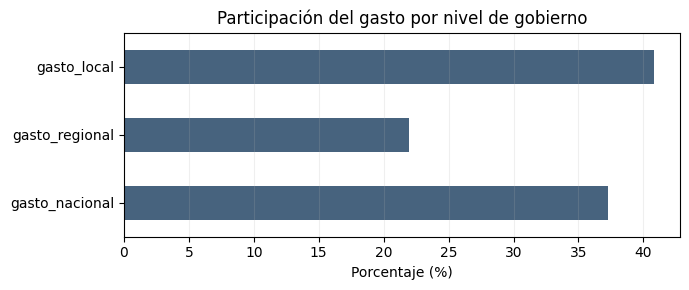

In [77]:
fig, eje = plt.subplots(figsize=(7, 3))
participacion.plot.barh(ax=eje, color="#47637e")
eje.set(title="Participación del gasto por nivel de gobierno", xlabel="Porcentaje (%)", ylabel="")
eje.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Estacionalidad del gasto
Comparamos el mismo mes entre distintos años, porque diciembre suele tener un comportamiento diferente del inicio del año.

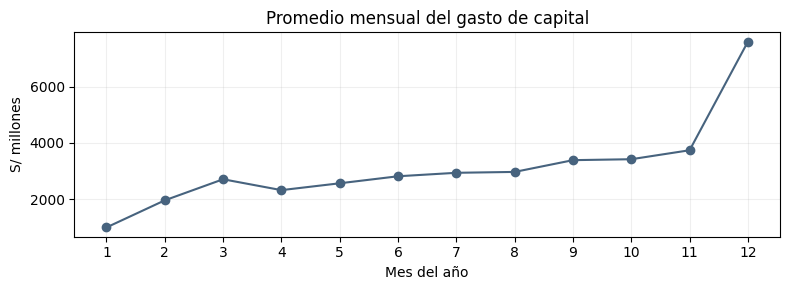

In [78]:
fig, eje = plt.subplots(figsize=(8, 3))
estacionalidad.plot(ax=eje, marker="o", color="#47637e")
eje.set(title="Promedio mensual del gasto de capital", xlabel="Mes del año", ylabel="S/ millones")
eje.set_xticks(range(1, 13))
eje.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Correlaciones
Relacionamos variaciones interanuales del gasto real con crecimiento del PBI, inflación y variación del tipo de cambio. Una correlación no demuestra causa y efecto.

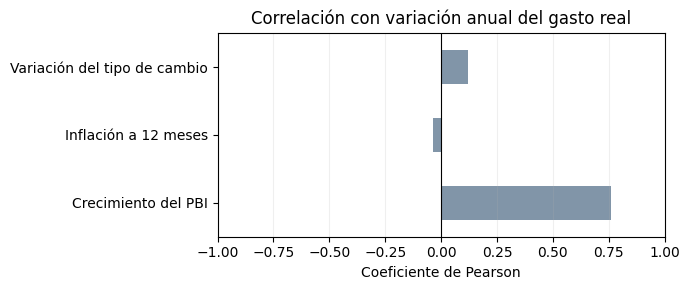

In [79]:
fig, eje = plt.subplots(figsize=(7, 3))
nombres_variables = {"crecimiento_pbi": "Crecimiento del PBI",
                     "inflacion": "Inflación a 12 meses",
                     "cambio_var12m": "Variación del tipo de cambio"}
correlaciones.rename(index=nombres_variables).plot.barh(ax=eje, color="#8195a8")
eje.axvline(0, color="black", linewidth=0.8)
eje.set(title="Correlación con variación anual del gasto real", xlabel="Coeficiente de Pearson", ylabel="")
eje.set_xlim(-1, 1)
eje.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Cuatro modelos para pronosticar
Probamos el promedio de tres años, Holt-Winters (ETS), SARIMA y el promedio simple de los dos últimos. Todos utilizan únicamente los datos anteriores al mes pronosticado.

In [80]:
def promedio_estacional(serie, fechas):
    """Promedia el mismo mes de los tres años anteriores."""
    datos = serie.tail(36)
    promedios = datos.groupby(datos.index.month).mean()
    valores = []
    for fecha in fechas:
        valores.append(promedios.loc[fecha.month])
    return pd.Series(valores, index=fechas)

def pronosticar_ets(serie, fechas):
    """Ajusta nivel, tendencia y patrón estacional."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        modelo = ExponentialSmoothing(np.log1p(serie), trend="add", damped_trend=True,
                                      seasonal="add", seasonal_periods=12).fit()
    return pd.Series(np.maximum(0, np.expm1(modelo.forecast(len(fechas)))), index=fechas)

In [81]:
def pronosticar_sarima(serie, fechas):
    """Compara cuatro órdenes sencillos y elige el de menor AIC."""
    opciones = [((0, 1, 1), (0, 1, 1, 12)), ((1, 1, 0), (0, 1, 1, 12)),
                ((1, 1, 1), (0, 1, 1, 12)), ((1, 1, 0), (1, 1, 0, 12))]
    mejor = None
    for orden, estacional in opciones:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                modelo = SARIMAX(np.log1p(serie), order=orden, seasonal_order=estacional,
                                 enforce_stationarity=False, enforce_invertibility=False)
                ajuste = modelo.fit(disp=False, maxiter=50)
            if np.isfinite(ajuste.aic) and (mejor is None or ajuste.aic < mejor.aic):
                mejor = ajuste
        except (ValueError, np.linalg.LinAlgError):
            continue
    if mejor is None:
        raise ValueError("No fue posible ajustar SARIMA con los datos disponibles.")
    return pd.Series(np.maximum(0, np.expm1(mejor.forecast(len(fechas)))), index=fechas)

In [82]:
def cuatro_modelos(serie, fechas):
    """Reúne los cuatro métodos para evaluarlos juntos."""
    resultados = {}
    resultados["Promedio 3 años"] = promedio_estacional(serie, fechas)
    resultados["ETS"] = pronosticar_ets(serie, fechas)
    resultados["SARIMA"] = pronosticar_sarima(serie, fechas)
    resultados["Ensamble simple"] = (resultados["ETS"] + resultados["SARIMA"]) / 2
    return resultados

## 7. Validación y elección del modelo
Para cada año de 2022 a 2025, entrenamos con los años anteriores y comparamos doce predicciones con sus valores reales. Elegimos el MAE menor y revisamos también sMAPE.

In [83]:
# Predecimos cuatro años diferentes sin mezclar futuro con pasado.
entrenamiento = historico["gasto_total"].asfreq("MS")
registros = []
for anio in ANIOS_VALIDACION:
    historia = entrenamiento.loc[:f"{anio - 1}-12"]
    fechas = pd.date_range(f"{anio}-01", periods=12, freq="MS")
    predicciones = cuatro_modelos(historia, fechas)
    for nombre, prediccion in predicciones.items():
        for fecha in fechas:
            registros.append([nombre, anio, fecha, entrenamiento.loc[fecha], prediccion.loc[fecha]])

validacion = pd.DataFrame(registros, columns=["modelo", "anio", "fecha", "real", "pronostico"])

In [84]:
def calcular_errores(datos):
    """Mide cuánto se apartó cada modelo de los meses reales."""
    error = datos["pronostico"] - datos["real"]
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    denominador = datos["pronostico"].abs() + datos["real"].abs()
    smape = (200 * error.abs() / denominador.replace(0, np.nan)).mean()
    anuales = datos.groupby("anio")[["real", "pronostico"]].sum()
    error_anual = (100 * (anuales["pronostico"] / anuales["real"] - 1).abs()).mean()
    return [datos["modelo"].iloc[0], mae, rmse, smape, error_anual]

filas = []
for nombre in validacion["modelo"].unique():
    filas.append(calcular_errores(validacion[validacion["modelo"] == nombre]))
comparacion = pd.DataFrame(filas, columns=["Modelo", "MAE", "RMSE", "sMAPE (%)", "Error anual (%)"])
comparacion = comparacion.sort_values("MAE").reset_index(drop=True)
mejor_modelo = comparacion.loc[0, "Modelo"]
comparacion.round(1)

,Modelo,MAE,RMSE,sMAPE (%),Error anual (%)
0,SARIMA,682.6,802.6,21.1,15.6
1,Ensamble simple,749.5,869.1,23.2,18.1
2,ETS,858.4,955.6,26.0,20.5
3,Promedio 3 años,956.5,1053.2,27.8,22.8


### ¿Por qué se eligió ese modelo?
El MAE resume el error mensual promedio en millones de soles. Si los dos mejores tienen errores parecidos, la elección no debe interpretarse como una ventaja absoluta.

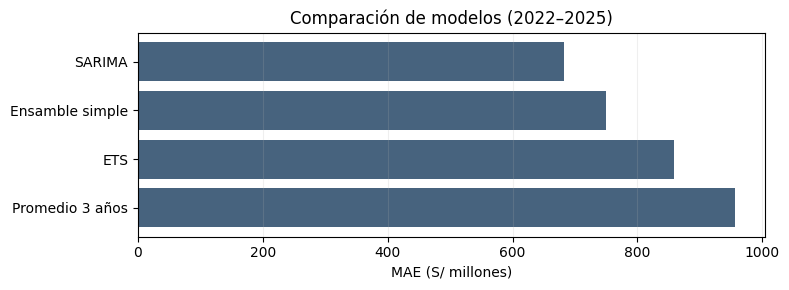

Ganó SARIMA. Reduce el MAE 8.9% frente a Ensamble simple.


In [85]:
fig, eje = plt.subplots(figsize=(8, 3))
eje.barh(comparacion["Modelo"], comparacion["MAE"], color="#47637e")
eje.invert_yaxis()
eje.set(title="Comparación de modelos (2022–2025)", xlabel="MAE (S/ millones)")
eje.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

segundo = comparacion.loc[1, "Modelo"]
ventaja = 100 * (comparacion.loc[1, "MAE"] - comparacion.loc[0, "MAE"]) / comparacion.loc[1, "MAE"]
print(f"Ganó {mejor_modelo}. Reduce el MAE {ventaja:.1f}% frente a {segundo}.")

## 8. Pronóstico de 2026 y datos observados
Entrenamos el método elegido hasta diciembre de 2025. Los meses de 2026 publicados por el BCRP se muestran aparte: sirven para comprobar el pronóstico, no para entrenarlo.

In [86]:
# Calculamos el pronóstico con el modelo seleccionado.
fechas_2026 = pd.date_range(INICIO_PRONOSTICO, FIN_PRONOSTICO, freq="MS")
pronosticos = cuatro_modelos(entrenamiento, fechas_2026)
pronostico_2026 = pd.DataFrame(index=fechas_2026)
pronostico_2026.index.name = "fecha"
pronostico_2026["Pronóstico"] = pronosticos[mejor_modelo]
pronostico_2026["Observado"] = datos_mensuales["gasto_total"].reindex(fechas_2026)

# Los rangos se basan en errores relativos de la validación.
pruebas = validacion[validacion["modelo"] == mejor_modelo].copy()
if (pruebas[["real", "pronostico"]] <= 0).any().any():
    raise ValueError("Los rangos relativos requieren valores positivos.")
factor = pruebas["real"] / pruebas["pronostico"]
for nivel, cola in [(80, 0.10), (90, 0.05)]:
    pronostico_2026[f"Inf. {nivel}%"] = pronostico_2026["Pronóstico"] * factor.quantile(cola)
    pronostico_2026[f"Sup. {nivel}%"] = pronostico_2026["Pronóstico"] * factor.quantile(1 - cola)

In [87]:
# Incorporamos el IPC observado y estimamos solo los meses no publicados.
ipc = datos_mensuales["ipc"].dropna()
ultimo_mes = ipc.index.max()
ultimo_valor = ipc.loc[ultimo_mes]
valor_anterior = ipc.loc[ultimo_mes - pd.DateOffset(months=12)]
tasa_mensual = (ultimo_valor / valor_anterior) ** (1 / 12) - 1
ipc_2026 = datos_mensuales["ipc"].reindex(fechas_2026).copy()
tipo_ipc = pd.Series("Observado", index=fechas_2026)
for fecha in fechas_2026:
    if pd.isna(ipc_2026.loc[fecha]):
        meses = (fecha.year - ultimo_mes.year) * 12 + fecha.month - ultimo_mes.month
        ipc_2026.loc[fecha] = ultimo_valor * (1 + tasa_mensual) ** meses
        tipo_ipc.loc[fecha] = "Estimado"

pronostico_2026["Pronóstico real"] = 100 * pronostico_2026["Pronóstico"] / ipc_2026
pronostico_2026["Observado real"] = 100 * pronostico_2026["Observado"] / ipc_2026
pronostico_2026["IPC utilizado"] = ipc_2026
pronostico_2026["Tipo IPC"] = tipo_ipc


### Gráfico principal: histórico, pronóstico e incertidumbre
Las bandas del 80 % y 90 % expresan la variación de los errores pasados. Son rangos orientativos, no garantías de que el gasto futuro caiga dentro de ellos.

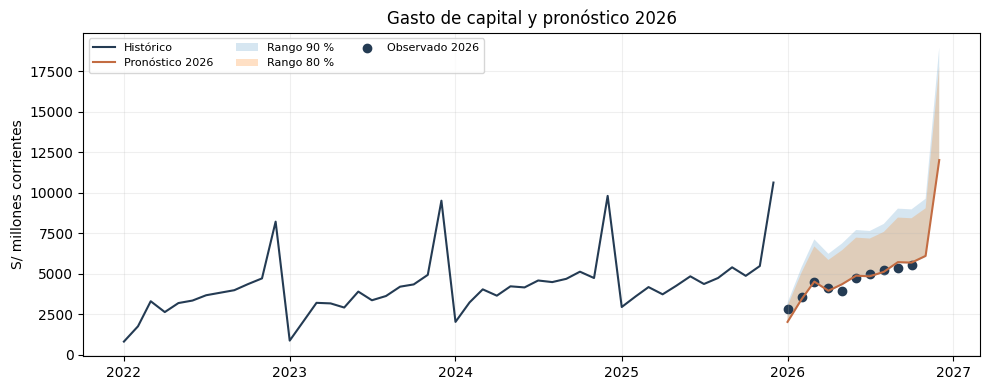

In [88]:
fig, eje = plt.subplots(figsize=(10, 4))
eje.plot(entrenamiento.loc["2022":], label="Histórico", color="#243b53")
eje.plot(pronostico_2026["Pronóstico"], label="Pronóstico 2026", color="#c36c42")
eje.fill_between(fechas_2026, pronostico_2026["Inf. 90%"], pronostico_2026["Sup. 90%"], alpha=0.18, label="Rango 90 %")
eje.fill_between(fechas_2026, pronostico_2026["Inf. 80%"], pronostico_2026["Sup. 80%"], alpha=0.24, label="Rango 80 %")
reales_2026 = pronostico_2026["Observado"].dropna()
if len(reales_2026):
    eje.scatter(reales_2026.index, reales_2026, label="Observado 2026", color="#243b53")
eje.set(title="Gasto de capital y pronóstico 2026", ylabel="S/ millones corrientes")
eje.legend(ncol=3, fontsize=8)
eje.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Tabla final
La tabla separa lo pronosticado de lo observado. Los valores reales expresados a precios de diciembre de 2021 utilizan el IPC de Lima; algunos meses del IPC pueden estar estimados.

In [89]:
# Presentamos únicamente los datos necesarios para interpretar la proyección.
tabla_final = pronostico_2026.round(1).copy()
tabla_final.index = tabla_final.index.strftime("%Y-%m")
tabla_final.index.name = "Mes"
tabla_final[["Pronóstico", "Inf. 80%", "Sup. 80%", "Inf. 90%", "Sup. 90%", "Observado"]]

,Pronóstico,Inf. 80%,Sup. 80%,Inf. 90%,Sup. 90%,Observado
Mes,,,,,,
2026-01,2025.6,2015.5,3001.0,1998.6,3196.3,2800.0
2026-02,3427.4,3410.3,5077.9,3381.8,5408.5,3576.5
2026-03,4513.5,4491.0,6687.0,4453.4,7122.3,4500.6
2026-04,3949.5,3929.8,5851.4,3896.9,6232.3,4131.1
2026-05,4351.3,4329.5,6446.6,4293.4,6866.3,3958.1
2026-06,4879.4,4855.0,7229.0,4814.4,7699.6,4755.3
2026-07,4840.4,4816.2,7171.3,4776.0,7638.1,4954.4
2026-08,5116.3,5090.7,7580.0,5048.2,8073.5,5227.6
2026-09,5714.9,5686.4,8466.9,5638.8,9018.1,5379.8


## 9. Conclusiones y límites

In [90]:
# Un mensaje final con las cifras principales del análisis.
pronostico_anual = pronostico_2026["Pronóstico"].sum()
meses_observados = int(pronostico_2026["Observado"].notna().sum())
mae = comparacion.loc[0, "MAE"]
print(f"Modelo ganador: {mejor_modelo} | MAE: S/ {mae:,.0f} millones | Pronóstico 2026: S/ {pronostico_anual:,.0f} millones")

Modelo ganador: SARIMA | MAE: S/ 683 millones | Pronóstico 2026: S/ 62,622 millones


## 10. PDF y Excel


In [91]:
# Herramientas para guardar el informe y las hojas de cálculo.
from datetime import datetime
from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor, white
from reportlab.lib.pagesizes import A4
from reportlab.platypus import Paragraph, Table, TableStyle
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.utils import ImageReader

FECHA_REPORTE = datetime.now().strftime("%d/%m/%Y")
AZUL = "#20364F"
GRIS = "#657589"
NARANJA = "#C07754"

### Tablas finales
Cada hoja contiene un resultado necesario para revisar o reproducir el trabajo. Se incluye el valor observado de 2026 cuando el BCRP ya lo publicó; lo demás sigue siendo pronóstico.

In [92]:
# Preparamos una tabla breve con los controles de calidad.
tabla_calidad = pd.DataFrame([
    ["Meses esperados", len(meses_esperados)], ["Meses sin gasto", int(faltantes)],
    ["Meses sin IPC", int(faltantes_ipc)],
    ["Diferencias del gasto > S/ 1 millón", int((diferencia.abs() > 1).sum())],
], columns=["Control", "Resultado"])


In [93]:
# Creamos tablas con encabezados y unidades fáciles de reconocer.
nombres = {"gasto_nacional": "Gobierno nacional", "gasto_regional": "Gobiernos regionales", "gasto_local": "Gobiernos locales"}
tabla_participacion = participacion.rename(index=nombres).reset_index()
tabla_participacion.columns = ["Nivel de gobierno", "Participación (%)"]
tabla_estacionalidad = estacionalidad.reset_index()
tabla_estacionalidad.columns = ["Mes", "Promedio (S/ millones)"]
tabla_correlaciones = correlaciones.reset_index()
tabla_correlaciones.columns = ["Indicador interanual", "Correlación Pearson"]
tabla_correlaciones["Indicador interanual"] = tabla_correlaciones["Indicador interanual"].replace(nombres_variables)
tabla_prueba = pronostico_2026.dropna(subset=["Observado"])[["Pronóstico", "Observado"]].copy()
tabla_prueba["Error (S/ millones)"] = tabla_prueba["Pronóstico"] - tabla_prueba["Observado"]

In [94]:
# Reunimos solamente las tablas de datos, validación y resultados.
tabla_proyeccion = pronostico_2026.reset_index()
tabla_base = datos_mensuales.loc[INICIO_ESTUDIO:FIN_CONSULTA].reset_index()
tabla_validacion = validacion.copy()
tabla_fuentes = pd.DataFrame([
    [nombre, codigo, f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/{codigo}/json", FECHA_REPORTE]
    for nombre, codigo in SERIES.items()
], columns=["Variable", "Código BCRP", "Enlace de consulta", "Fecha del informe"])
tablas = {
    "base_mensual": tabla_base, "calidad": tabla_calidad,
    "participacion": tabla_participacion,
    "estacionalidad": tabla_estacionalidad, "correlaciones": tabla_correlaciones,
    "validacion_mensual": tabla_validacion, "comparacion_modelos": comparacion,
    "pronostico_2026": tabla_proyeccion,
    "prueba_real_2026": tabla_prueba.reset_index(),
    "fuentes_bcrp": tabla_fuentes,
}


In [95]:
def exportar_excel(tablas):
    """Guarda las hojas con encabezados azules y valores legibles."""
    ruta = CARPETA / "Resultados_Data.xlsx"
    with pd.ExcelWriter(ruta, engine="xlsxwriter", datetime_format="yyyy-mm-dd") as escritor:
        libro = escritor.book
        titulo = libro.add_format({"bold": True, "font_color": "white", "bg_color": AZUL, "font_size": 13})
        cabecera = libro.add_format({"bold": True, "font_color": "white", "bg_color": AZUL, "text_wrap": True})
        numero = libro.add_format({"num_format": "#,##0.00"})
        for nombre, tabla in tablas.items():
            tabla.to_excel(escritor, sheet_name=nombre, startrow=2, index=False)
            hoja = escritor.sheets[nombre]
            ultima_col = len(tabla.columns) - 1
            hoja.merge_range(0, 0, 0, ultima_col, nombre.replace("_", " ").upper(), titulo)
            for i, columna in enumerate(tabla.columns):
                hoja.write(2, i, columna, cabecera)
                ancho = min(max(16, len(columna) + 3), 36)
                if "Enlace" in columna:
                    ancho = 62
                if columna in ["Evidencia o motivo", "Explicación"]:
                    ancho = 48
                hoja.set_column(i, i, ancho, numero)
            hoja.freeze_panes(3, 0)
            hoja.autofilter(2, 0, len(tabla) + 2, ultima_col)
    return ruta

In [96]:
def graficos_resumen():
    """Guarda dos figuras claras para el PDF de tres páginas."""
    ruta_estacional = CARPETA / "estacionalidad.png"
    ruta_proyeccion = CARPETA / "pronostico.png"
    fig, eje = plt.subplots(figsize=(8.5, 2.6))
    eje.bar(range(1, 13), estacionalidad.values, color=AZUL)
    eje.set(title="Gasto promedio por mes (2015–2025)", xlabel="Mes del año", ylabel="S/ millones")
    eje.set_xticks(range(1, 13))
    eje.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(ruta_estacional, dpi=160)
    plt.close(fig)
    fig, eje = plt.subplots(figsize=(9.0, 3.1))
    eje.plot(entrenamiento.loc["2023":], color=AZUL, label="Histórico")
    eje.plot(pronostico_2026["Pronóstico"], color=NARANJA, label="Pronóstico 2026")
    eje.fill_between(fechas_2026, pronostico_2026["Inf. 90%"], pronostico_2026["Sup. 90%"], alpha=0.13, color=NARANJA, label="Rango 90 %")
    eje.fill_between(fechas_2026, pronostico_2026["Inf. 80%"], pronostico_2026["Sup. 80%"], alpha=0.22, color=NARANJA, label="Rango 80 %")
    eje.scatter(tabla_prueba.index, tabla_prueba["Observado"], color=AZUL, s=18, label="Real 2026")
    eje.set(title="Ejecución observada y pronóstico 2026", ylabel="S/ millones corrientes")
    eje.grid(alpha=0.2)
    eje.legend(ncol=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(ruta_proyeccion, dpi=160)
    plt.close(fig)
    return ruta_estacional, ruta_proyeccion

In [97]:
def encabezado_pdf(pdf, titulo, subtitulo, pagina):
    """Dibuja un encabezado claro y numera cada página."""
    pdf.setFillColor(HexColor(AZUL))
    pdf.rect(0, 818, 595, 24, fill=1, stroke=0)
    pdf.setFont("Helvetica-Bold", 20)
    pdf.drawString(42, 779, titulo)
    pdf.setFillColor(HexColor(GRIS))
    pdf.setFont("Helvetica", 10)
    pdf.drawString(42, 759, subtitulo)
    pdf.setStrokeColor(HexColor("#DCE3EA"))
    pdf.line(42, 48, 553, 48)
    pdf.setFont("Helvetica", 8)
    pdf.drawString(42, 33, f"Fuente: BCRP, PN02210FM y otras series | Informe: {FECHA_REPORTE}")
    pdf.drawRightString(553, 33, f"Página {pagina}/3")

In [98]:
def texto_pdf(pdf, texto, x, y, ancho=510, tamano=10):
    """Escribe un párrafo y calcula automáticamente su altura."""
    estilo = ParagraphStyle("cuerpo", fontName="Helvetica", fontSize=tamano,
                            leading=tamano * 1.42, textColor=HexColor(AZUL))
    parrafo = Paragraph(texto, estilo)
    _, alto = parrafo.wrap(ancho, 700)
    parrafo.drawOn(pdf, x, y - alto)
    return y - alto - 12

def subtitulo_pdf(pdf, titulo, y):
    """Separa cada idea del informe sin usar demasiado texto."""
    pdf.setFillColor(HexColor(AZUL))
    pdf.setFont("Helvetica-Bold", 12)
    pdf.drawString(42, y, titulo)
    return y - 18

In [99]:
def tabla_pdf(pdf, encabezados, filas, x, y, anchos, fuente=8):
    """Coloca una tabla compacta con encabezado azul."""
    filas_texto = [[str(x) for x in encabezados]]
    for fila in filas:
        filas_texto.append([str(x) for x in fila])
    tabla = Table(filas_texto, colWidths=anchos, rowHeights=19)
    tabla.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), HexColor(AZUL)),
        ("TEXTCOLOR", (0, 0), (-1, 0), white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), fuente),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LINEBELOW", (0, 1), (-1, -1), 0.35, HexColor("#CDD5DD")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [white, HexColor("#F3F6F9")]),
    ]))
    altura = 19 * len(filas_texto)
    tabla.wrapOn(pdf, sum(anchos), altura)
    tabla.drawOn(pdf, x, y - altura)
    return y - altura - 15

In [100]:
def pagina_resumen(pdf):
    """Presenta el panorama fiscal y qué utilidad tiene el análisis."""
    encabezado_pdf(pdf, "Gasto de capital en el Perú", "Resultados clave · 2015–2025 y seguimiento 2026", 1)
    y = subtitulo_pdf(pdf, "¿Qué analiza el proyecto?", 724)
    y = texto_pdf(pdf, "Estudiamos la <b>formación bruta de capital del Gobierno General</b> (serie PN02210FM), expresada en millones de soles nominales. Comparamos su comportamiento mensual y cuatro métodos de pronóstico.", 42, y)
    observados = pronostico_2026["Observado"].dropna()
    total_2026 = observados.sum()
    referencia = historico[historico.index.month.isin(observados.index.month)]
    referencia = referencia[referencia.index.year == 2025]["gasto_total"].sum()
    cambio = 100 * (total_2026 / referencia - 1) if referencia > 0 else None
    y = subtitulo_pdf(pdf, "Tres cifras para entender los resultados", y - 8)
    periodo = f"ene–{observados.index.max():%m}" if len(observados) else "sin datos"
    valor_real = f"S/ {total_2026:,.0f} millones" if len(observados) else "No publicado"
    valor_cambio = f"{cambio:+.1f}%" if cambio is not None else "s/d"
    datos = [(f"Observado 2026 ({len(observados)} meses)", valor_real),
             ("Cambio frente a los mismos meses de 2025", valor_cambio),
             ("Proyección anual 2026", f"S/ {pronostico_anual:,.0f} millones")]
    for titulo, valor in datos:
        pdf.setFillColor(HexColor("#F0F4F7"))
        pdf.roundRect(42, y - 54, 511, 51, 6, fill=1, stroke=0)
        pdf.setFillColor(HexColor(AZUL))
        pdf.setFont("Helvetica", 10)
        pdf.drawString(54, y - 22, titulo)
        pdf.setFont("Helvetica-Bold", 15)
        pdf.drawRightString(542, y - 32, valor)
        y -= 61
    y = subtitulo_pdf(pdf, "¿Qué encontramos?", y - 9)
    lider = tabla_participacion.sort_values("Participación (%)", ascending=False).iloc[0]
    y = texto_pdf(pdf, f"La mayor participación correspondió a <b>{lider['Nivel de gobierno']}</b> ({lider['Participación (%)']:.1f}%). El promedio mensual histórico fue de S/ {gasto_promedio:,.0f} millones.", 42, y)
    y = texto_pdf(pdf, f"El modelo <b>{mejor_modelo}</b> obtuvo el menor MAE ({mae:,.0f} millones por mes). El pronóstico anual es una estimación estadística, no una ejecución confirmada.", 42, y)
    y = subtitulo_pdf(pdf, "¿Para qué puede utilizarse?", y - 5)
    y = texto_pdf(pdf, "Sirve para comparar el ritmo mensual del gasto, reconocer meses de alta ejecución y dar seguimiento a los valores publicados. No evalúa la calidad de las obras ni establece relaciones de causa y efecto.", 42, y)
    texto_pdf(pdf, f"<b>Curso:</b> {CURSO}. <b>Equipo:</b> {INTEGRANTES}.", 42, y, tamano=9)
    pdf.showPage()

In [101]:
def pagina_modelos(pdf, imagen_estacional):
    """Explica la estacionalidad y por qué fue elegido el modelo."""
    encabezado_pdf(pdf, "Por qué se eligió el modelo", "Estacionalidad y comparación con las mismas pruebas", 2)
    y = subtitulo_pdf(pdf, "1. El gasto tiene un calendario marcado", 723)
    pdf.drawImage(ImageReader(str(imagen_estacional)), 45, 512, width=505, height=185)
    mes_max = int(estacionalidad.idxmax())
    mes_min = int(estacionalidad.idxmin())
    meses_es = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
    y = texto_pdf(pdf, f"{meses_es[mes_max - 1].capitalize()} tuvo el mayor promedio (S/ {estacionalidad.max():,.0f} millones) y {meses_es[mes_min - 1]} el menor (S/ {estacionalidad.min():,.0f} millones). Por eso evaluamos métodos que consideran patrones de doce meses.", 42, 502)
    y = subtitulo_pdf(pdf, "2. Cuatro modelos, misma validación", y - 2)
    filas = []
    for _, r in comparacion.iterrows():
        filas.append([r["Modelo"], f'{r["MAE"]:,.0f}', f'{r["RMSE"]:,.0f}', f'{r["sMAPE (%)"]:.1f}%', f'{r["Error anual (%)"]:.1f}%'])
    y = tabla_pdf(pdf, ["Modelo", "MAE", "RMSE", "sMAPE", "Error anual"], filas, 42, y, [170, 82, 82, 83, 94])
    diferencia = 100 * (comparacion.loc[1, "MAE"] - comparacion.loc[0, "MAE"]) / comparacion.loc[1, "MAE"]
    frase = "una diferencia pequeña" if diferencia < 5 else "una diferencia apreciable"
    y = texto_pdf(pdf, f"Ganó <b>{mejor_modelo}</b> porque tuvo menor MAE. Frente al segundo lugar, su MAE fue {diferencia:.1f}% menor ({frase}). La elección puede cambiar con otros datos o periodos de prueba.", 42, y)
    y = subtitulo_pdf(pdf, "3. Variables económicas: relación, no causa", y - 3)
    indicadores = []
    for _, r in tabla_correlaciones.iterrows():
        indicadores.append(f'{r["Indicador interanual"]}: {r["Correlación Pearson"]:+.2f}')
    texto_pdf(pdf, "Correlaciones de la variación interanual del gasto real con indicadores económicos: " + "; ".join(indicadores) + ". Son asociaciones y no implican efectos causales.", 42, y, tamano=9)
    pdf.showPage()

In [102]:
def pagina_pronostico(pdf, imagen_proyeccion):
    """Muestra el rango de incertidumbre y la comparación con 2026."""
    encabezado_pdf(pdf, "Pronóstico de 2026", "Estimación desde diciembre de 2025 y meses publicados", 3)
    pdf.drawImage(ImageReader(str(imagen_proyeccion)), 43, 520, width=511, height=204)
    y = texto_pdf(pdf, "La línea de pronóstico se calculó usando solo la historia hasta 2025. Los puntos observados son datos publicados de 2026; los rangos del 80% y 90% se construyeron con errores de validación y son orientativos.", 42, 509, tamano=9)
    y = subtitulo_pdf(pdf, "Detalle mensual (S/ millones nominales)", y - 1)
    meses_cortos = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
    filas = []
    for fecha, r in pronostico_2026.iterrows():
        real = "s/d" if pd.isna(r["Observado"]) else f'{r["Observado"]:,.0f}'
        filas.append([meses_cortos[fecha.month - 1], f'{r["Pronóstico"]:,.0f}', real,
                      f'{r["Inf. 80%"]:,.0f}', f'{r["Sup. 80%"]:,.0f}',
                      f'{r["Inf. 90%"]:,.0f}', f'{r["Sup. 90%"]:,.0f}'])
    y = tabla_pdf(pdf, ["Mes", "Proy.", "Observ.", "Inf.80", "Sup.80", "Inf.90", "Sup.90"], filas, 42, y, [51, 73, 72, 75, 75, 82, 83], fuente=7)
    observados = pronostico_2026["Observado"].dropna()
    mixto = observados.sum() + pronostico_2026.loc[pronostico_2026["Observado"].isna(), "Pronóstico"].sum()
    y = texto_pdf(pdf, f"<b>Pronóstico original:</b> S/ {pronostico_anual:,.0f} millones. <b>Observado + meses restantes proyectados:</b> S/ {mixto:,.0f} millones (referencia mixta, no otro modelo).", 42, y, tamano=9)
    texto_pdf(pdf, "Los valores en soles reales se incluyen en el Excel y se deflactan con el IPC de Lima. Si faltan índices de 2026, se identifican como estimados; no son datos observados.", 42, y, tamano=8)
    pdf.showPage()

In [103]:
def crear_pdf(informe_estacional, informe_proyeccion):
    """Construye el informe breve con valores calculados en esta ejecución."""
    ruta = CARPETA / "Resultados_Data.pdf"
    pdf = canvas.Canvas(str(ruta), pagesize=A4)
    pdf.setTitle("Resumen visual - Gasto de capital del Perú")
    pagina_resumen(pdf)
    pagina_modelos(pdf, informe_estacional)
    pagina_pronostico(pdf, informe_proyeccion)
    pdf.save()
    return ruta

In [104]:
# Guardamos un PDF visual y un Excel con todas las tablas.
ruta_excel = exportar_excel(tablas)
imagen_estacional, imagen_proyeccion = graficos_resumen()
ruta_pdf = crear_pdf(imagen_estacional, imagen_proyeccion)
print("Listos: un PDF y un Excel.")

Listos: un PDF y un Excel.


In [105]:
# Descargamos solo el PDF y el Excel al terminar en Google Colab.
if DESCARGAR_AUTOMATICO:
    try:
        from google.colab import files
        files.download(str(ruta_pdf))
        files.download(str(ruta_excel))
    except ImportError:
        print(f"Los archivos están guardados en: {CARPETA.resolve()}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>